# SIMPEL: winter climate and sensitivity comparison

This notebook compares the dry hourly forcing (`example_hourly_winter/`) with its rainfall scenario (`example_hourly_winter_rain/`). The meteorology is a **synthetic, Germany-like January scenario**, not observed data: mean air temperature 2 °C, mean daily KDOWN peak around 140 W/m², LDOWN around 290–295 W/m², and wind around 4.5 m/s at 10 m. Rain events in the wet scenario are 10, 20, and 40 mm at noon on 15–17 January.

Run the sensitivity analysis for both scenarios before plotting:

```sh
./sensitivity.sh example_hourly_winter/
./sensitivity.sh example_hourly_winter_rain/
```

The first table lists every parameter value used in each sensitivity run. The figures then compare precipitation, monthly water-balance summaries, overall response ranges by parameter, and response curves for ETaTotal, Runoff_total, and Seepage.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

PROJECT_ROOT_OVERRIDE = None  # Set a path here if automatic project detection is ambiguous.


def find_project_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    current = Path.cwd()
    for candidate in (current, *current.parents):
        if (candidate / "sensitivity.sh").is_file():
            return candidate
    child_projects = [candidate for candidate in current.iterdir()
                      if candidate.is_dir() and (candidate / "sensitivity.sh").is_file()]
    if len(child_projects) == 1:
        return child_projects[0]
    raise FileNotFoundError(
        "Could not identify the project folder. Set PROJECT_ROOT_OVERRIDE to the folder containing sensitivity.sh."
    )


PROJECT_ROOT = find_project_root()
SCENARIOS = {"No rain": "example_hourly_winter", "Rain event": "example_hourly_winter_rain"}
SCENARIO_COLORS = {"No rain": "#E69F00", "Rain event": "#0072B2"}  # orange, blue
LEVEL_ORDER = ["minimum", "midpoint_low", "default", "midpoint_high", "maximum"]
LEVEL_LABELS = ["Minimum", "Mid-low", "Default", "Mid-high", "Maximum"]
SENSITIVITY_METRICS = ["ETaTotal", "Runoff_total", "Seepage"]


def latest_output_file(input_dir, filename):
    candidates = [
        folder / filename
        for folder in input_dir.iterdir()
        if folder.is_dir()
        and re.fullmatch(r"output_\d{8}_\d{6}", folder.name)
        and (folder / filename).is_file()
    ]
    if not candidates:
        raise FileNotFoundError(
            f"No {filename} found under timestamped output folders in {input_dir}. "
            "Run the model and sensitivity script first."
        )
    # Timestamped folder names sort chronologically; file mtimes can change when files are copied.
    return max(candidates, key=lambda path: path.parent.name)


def parse_hourly_dates(series):
    return pd.to_datetime(series, format="%d.%m.%Y.%H", errors="coerce")


forcing = {}
model_outputs = {}
sensitivity = {}
monthly_tables = []
for scenario, folder in SCENARIOS.items():
    input_dir = PROJECT_ROOT / folder
    if not input_dir.is_dir():
        raise FileNotFoundError(f"Scenario input directory not found: {input_dir}")

    forcing_data = pd.read_csv(input_dir / "Global_Input.txt", sep="\t")
    forcing_data["DateTime"] = parse_hourly_dates(forcing_data["Date"])
    if forcing_data["DateTime"].isna().any():
        raise ValueError(f"Could not parse every hourly date in {input_dir / 'Global_Input.txt'}")
    forcing[scenario] = forcing_data

    model_path = latest_output_file(input_dir, "SIMPLE_bucket_model.csv")
    model_data = pd.read_csv(model_path, sep="\t")
    model_data["DateTime"] = parse_hourly_dates(model_data["Date"])
    if model_data["DateTime"].isna().any():
        raise ValueError(f"Could not parse every model output date in {model_path}")
    model_outputs[scenario] = model_data

    sensitivity_path = latest_output_file(input_dir, "sensitivity_oat.csv")
    sensitivity_data = pd.read_csv(sensitivity_path, sep="\t")
    required = {"parameter", "level", "value", "note"}
    missing = required.difference(sensitivity_data.columns)
    if missing:
        raise ValueError(f"{sensitivity_path} is missing columns: {sorted(missing)}")
    sensitivity[scenario] = sensitivity_data

    model_data["Month"] = model_data["DateTime"].dt.to_period("M").astype(str)
    flux_columns = [name for name in [
        "Precipitation", "ETaTotal", "ETa", "I-Leaf", "I-Litter", "Seepage",
        "Surface_runoff", "Runoff_total",
    ] if name in model_data.columns]
    monthly = model_data.groupby("Month", sort=True)[flux_columns].sum()
    if "Storage" in model_data.columns:
        monthly["Storage_end"] = model_data.groupby("Month", sort=True)["Storage"].last()
    monthly.insert(0, "Condition", scenario)
    monthly_tables.append(monthly.reset_index())

monthly_summary = pd.concat(monthly_tables, ignore_index=True)
parameter_order = [
    parameter for parameter in sensitivity["No rain"]["parameter"].drop_duplicates()
    if parameter.lower() != "base"
]
value_tables = []
for scenario, table in sensitivity.items():
    changed = table.loc[table["parameter"].str.lower() != "base"].copy()
    missing_levels = {
        parameter: sorted(set(LEVEL_ORDER).difference(group["level"]))
        for parameter, group in changed.groupby("parameter")
        if set(LEVEL_ORDER).difference(group["level"])
    }
    if missing_levels:
        raise ValueError(f"{scenario} is missing sensitivity levels: {missing_levels}")
    if set(changed["parameter"]) != set(parameter_order):
        raise ValueError(f"Parameter set differs between scenarios in {scenario}.")
    changed["Condition"] = scenario
    changed["Level"] = pd.Categorical(changed["level"], LEVEL_ORDER, ordered=True)
    changed["Parameter"] = pd.Categorical(changed["parameter"], parameter_order, ordered=True)
    value_tables.append(changed.rename(columns={"value": "Value", "note": "Note"})[
        ["Condition", "Parameter", "Level", "Value", "Note"]
    ])

variable_values = pd.concat(value_tables, ignore_index=True).sort_values(
    ["Parameter", "Level", "Condition"]
).reset_index(drop=True)
available_metrics = [
    metric for metric in SENSITIVITY_METRICS
    if all(f"{metric}_change_%" in table.columns for table in sensitivity.values())
]
if not available_metrics:
    raise ValueError("No selected sensitivity change columns were found in both scenarios.")

print(f"Project: {PROJECT_ROOT}")
print("Loaded forcing, model outputs and sensitivity tables for both conditions.")

Project: /mnt/c/Users/hswt603qia/IdeaProjects/Simpel
Loaded forcing, model outputs and sensitivity tables for both conditions.


## Parameter values used

This tidy table lists every perturbed parameter, tested level, and actual value used in both scenarios. The combined LAI row is the value assigned to **both** `MinLAI` and `MaxLAI`. Notes indicate any coupled adjustment.

In [13]:
display(variable_values.fillna(""))


,Condition,Parameter,Level,Value,Note
0,No rain,Root Depth,minimum,1.0,
1,Rain event,Root Depth,minimum,1.0,
2,No rain,Root Depth,midpoint_low,50.5,
3,Rain event,Root Depth,midpoint_low,50.5,
4,No rain,Root Depth,default,100.0,
...,...,...,...,...,...
305,Rain event,Kmax,default,1200.0,
306,No rain,Kmax,midpoint_high,1600.0,
307,Rain event,Kmax,midpoint_high,1600.0,
308,No rain,Kmax,maximum,2000.0,


## Forcing precipitation and monthly water-balance summary

Figure 1 shows the hourly precipitation series for the two conditions. The monthly table summarizes model fluxes and end-of-month soil storage.

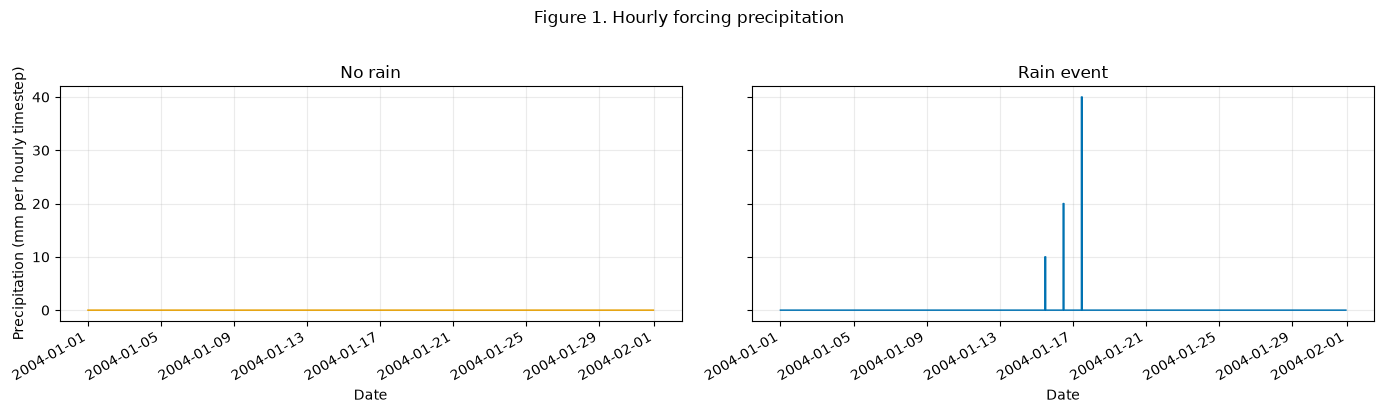

,Month,Condition,Precipitation,ETaTotal,ETa,I-Leaf,I-Litter,Seepage,Surface_runoff,Runoff_total,Storage_end
0,2004-01,No rain,0.0,5.31,5.31,0.0,0.0,41.17,0.00,41.17,193.52
1,2004-01,Rain event,70.0,6.44,5.15,1.3,0.0,41.80,66.89,108.69,194.87


In [14]:
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(14, 4), sharey=True)
for ax, (scenario, forcing_data) in zip(axes, forcing.items()):
    ax.step(forcing_data["DateTime"], forcing_data["P"], where="mid", linewidth=1.1,
            color=SCENARIO_COLORS[scenario])
    ax.set_title(scenario)
    ax.set_xlabel("Date")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Precipitation (mm per hourly timestep)")
fig.suptitle("Figure 1. Hourly forcing precipitation", y=1.02)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()

monthly_summary.round(2)

## Sensitivity range by parameter

Figure 2 compares each condition's largest absolute response across the five tested levels for ETaTotal, Runoff_total, and Seepage. The orange and blue bars share one figure-level legend. The response figures that follow retain the signed change at each level.

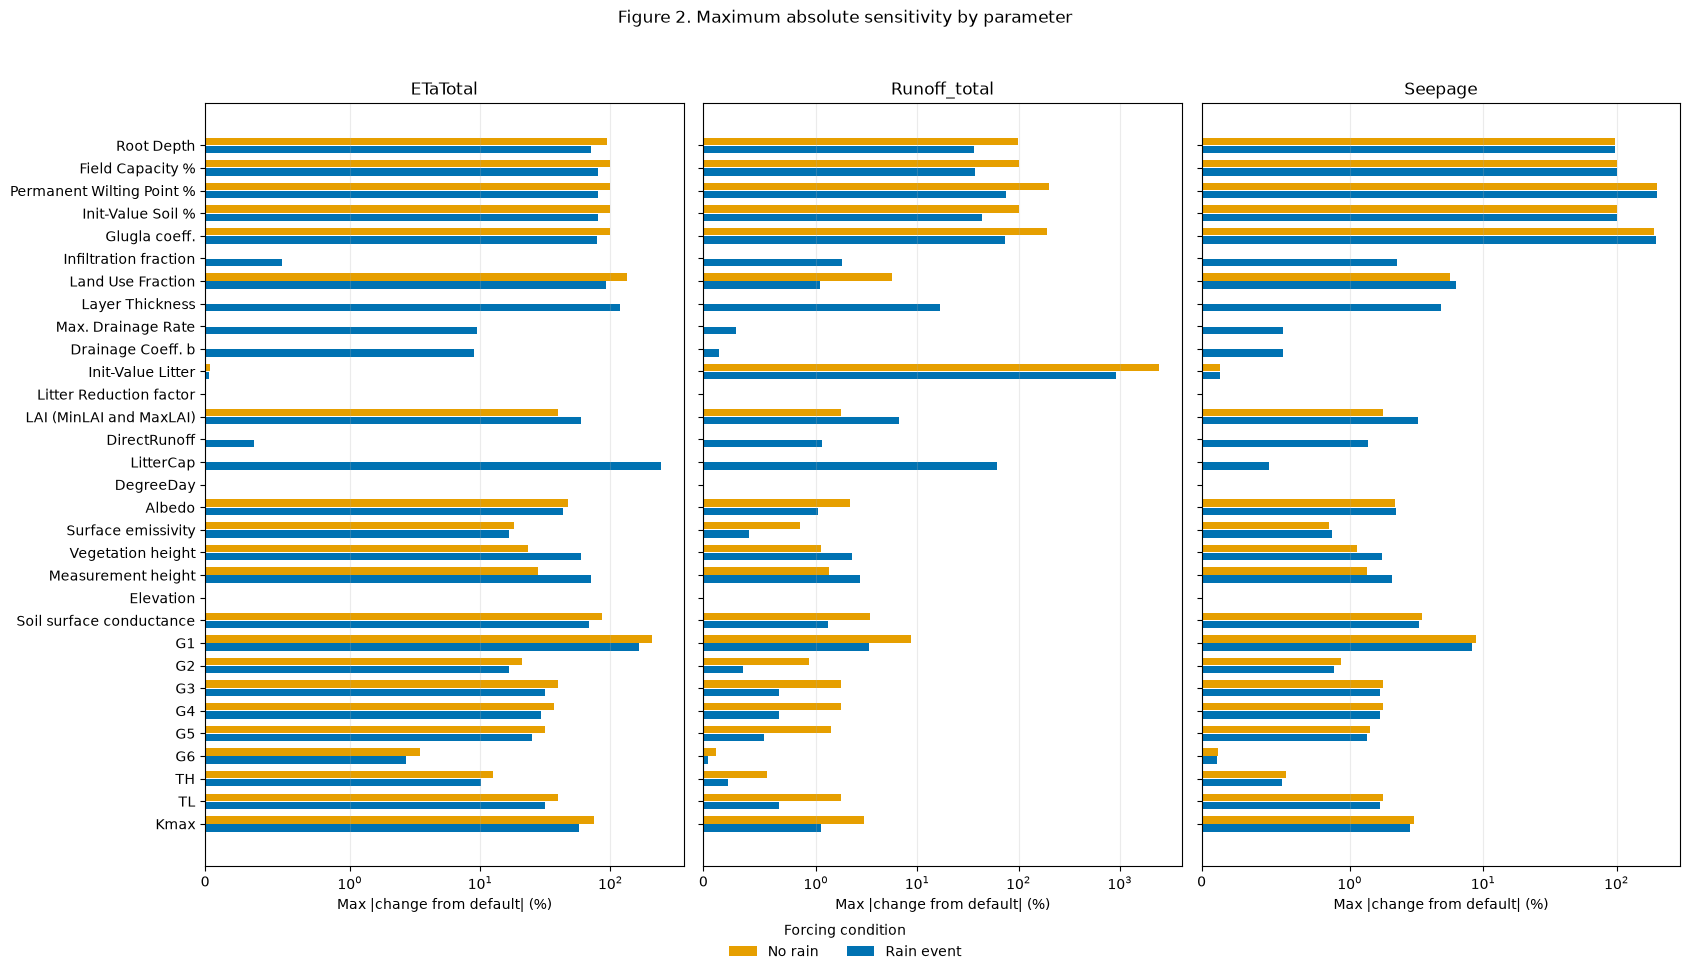

In [15]:
parameter_positions = np.arange(len(parameter_order))
bar_height = 0.36
fig_height = max(9, 0.32 * len(parameter_order))
fig, axes = plt.subplots(1, len(available_metrics), figsize=(17, fig_height), sharey=True)
if len(available_metrics) == 1:
    axes = [axes]

for ax, metric in zip(axes, available_metrics):
    change_column = f"{metric}_change_%"
    for scenario_index, scenario in enumerate(SCENARIOS):
        changed = sensitivity[scenario]
        changed = changed.loc[changed["parameter"].str.lower() != "base"]
        response = changed.groupby("parameter", sort=False)[change_column].apply(
            lambda values: values.abs().max()
        ).reindex(parameter_order)
        offset = (scenario_index - (len(SCENARIOS) - 1) / 2) * bar_height
        ax.barh(parameter_positions + offset, response, height=bar_height * 0.9,
                color=SCENARIO_COLORS[scenario], label=scenario)
    ax.set_title(metric)
    ax.set_xlabel("Max |change from default| (%)")
    ax.set_xscale("symlog", linthresh=1)
    ax.grid(axis="x", alpha=0.25)
    ax.invert_yaxis()

axes[0].set_yticks(parameter_positions, parameter_order)
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)
legend_handles = [Patch(facecolor=SCENARIO_COLORS[name], label=name) for name in SCENARIOS]
fig.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 0.015),
           ncol=len(legend_handles), frameon=False, title="Forcing condition")
fig.suptitle("Figure 2. Maximum absolute sensitivity by parameter", y=0.985)
fig.tight_layout(rect=(0, 0.06, 1, 0.96))
plt.show()

## Output response at each tested parameter value

Figures 3–5 show each metric against the tested value for every parameter. Each parameter is varied independently; both LAI limits are assigned the same tested value. Scenario colors are consistent throughout: orange for no rain and blue for the rain events.

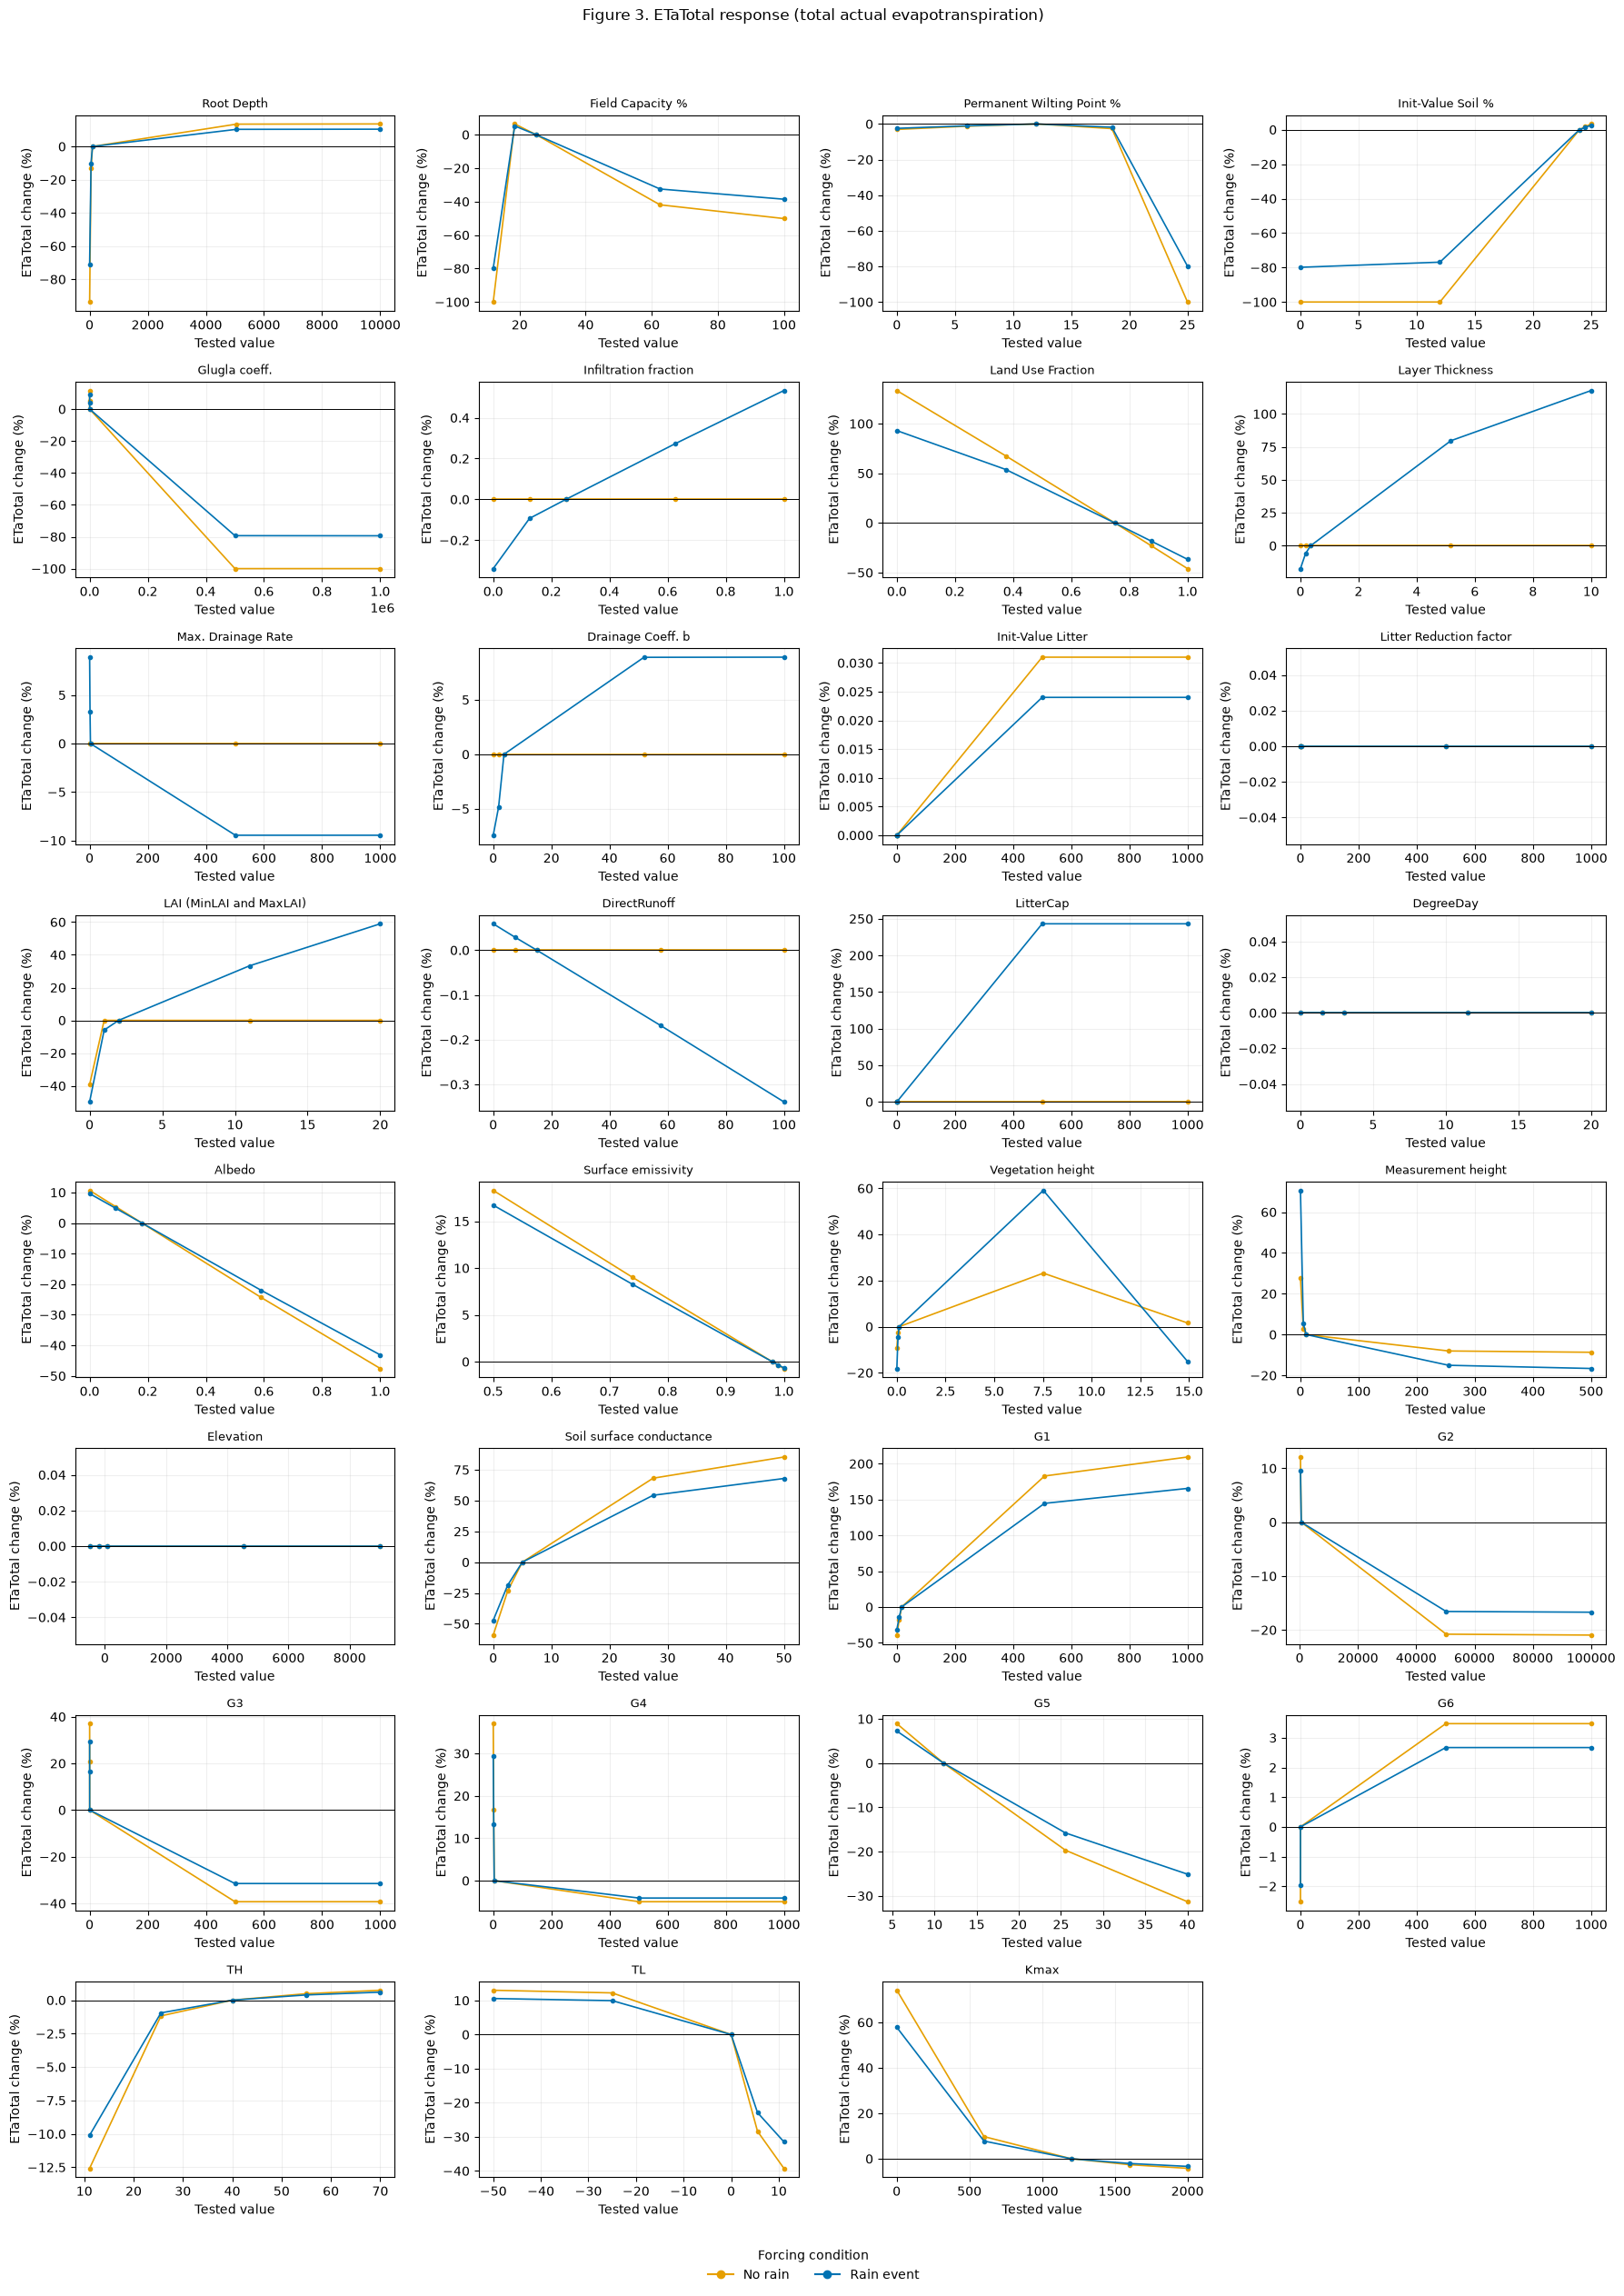

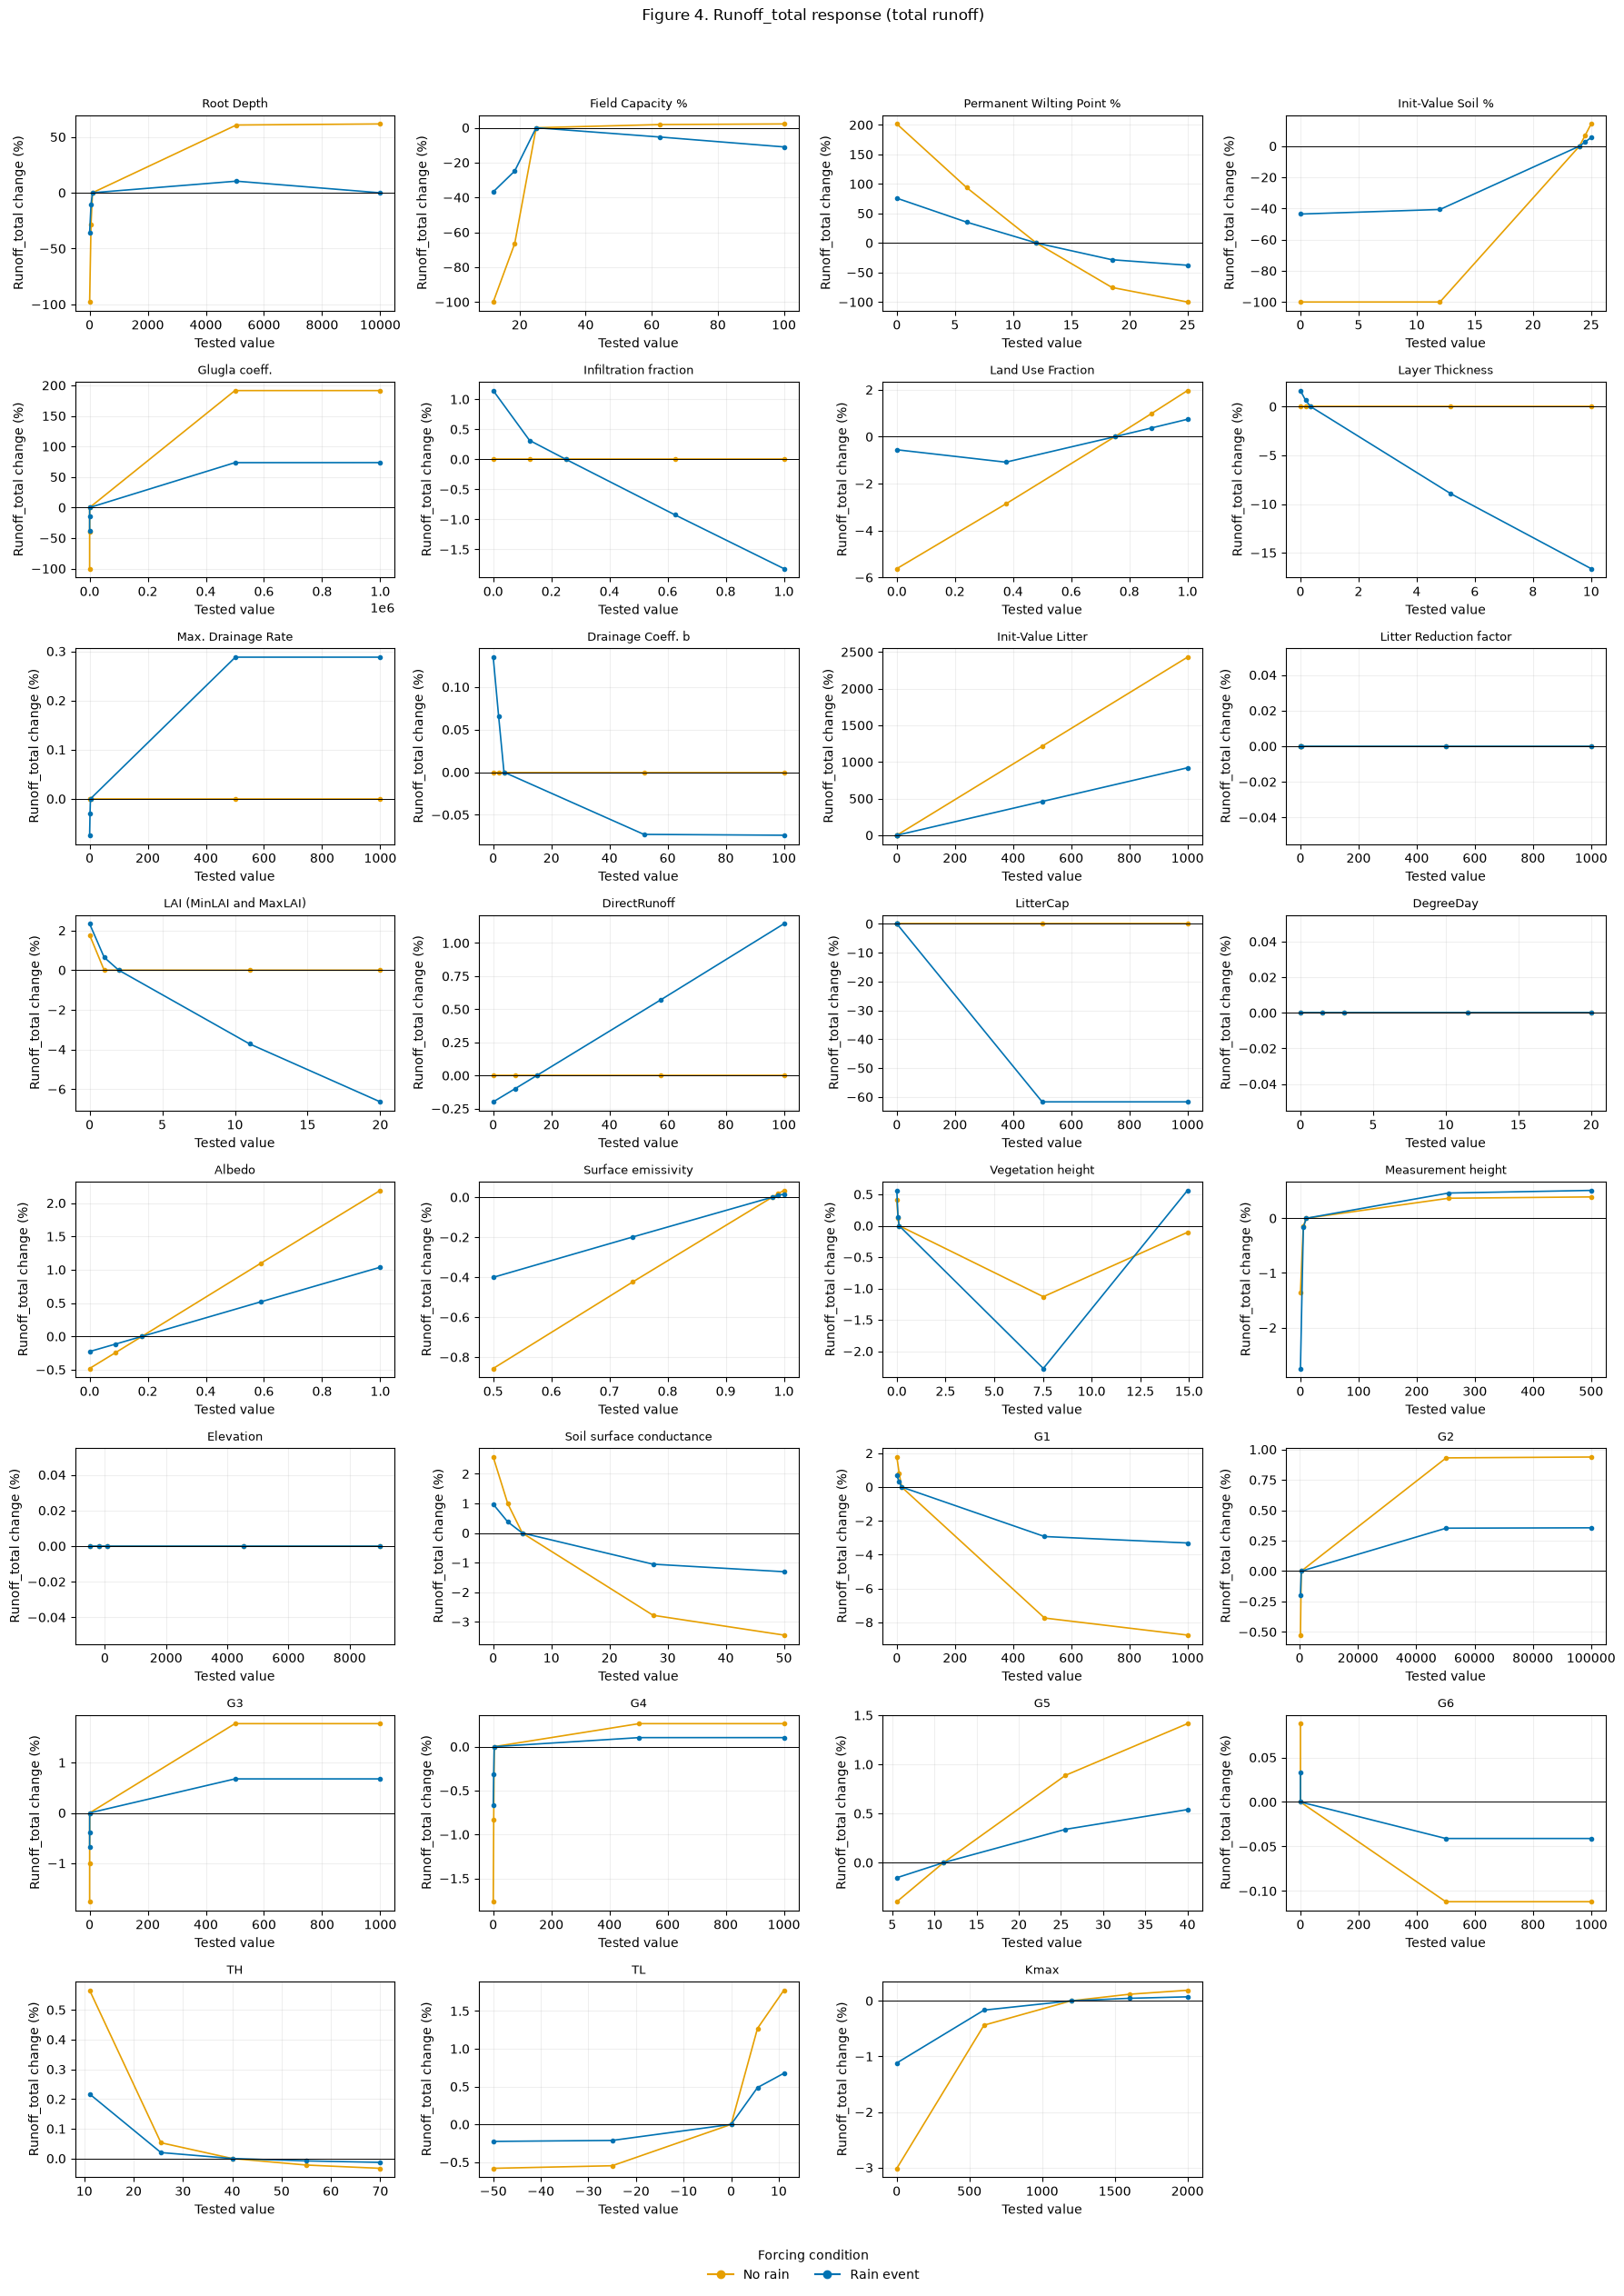

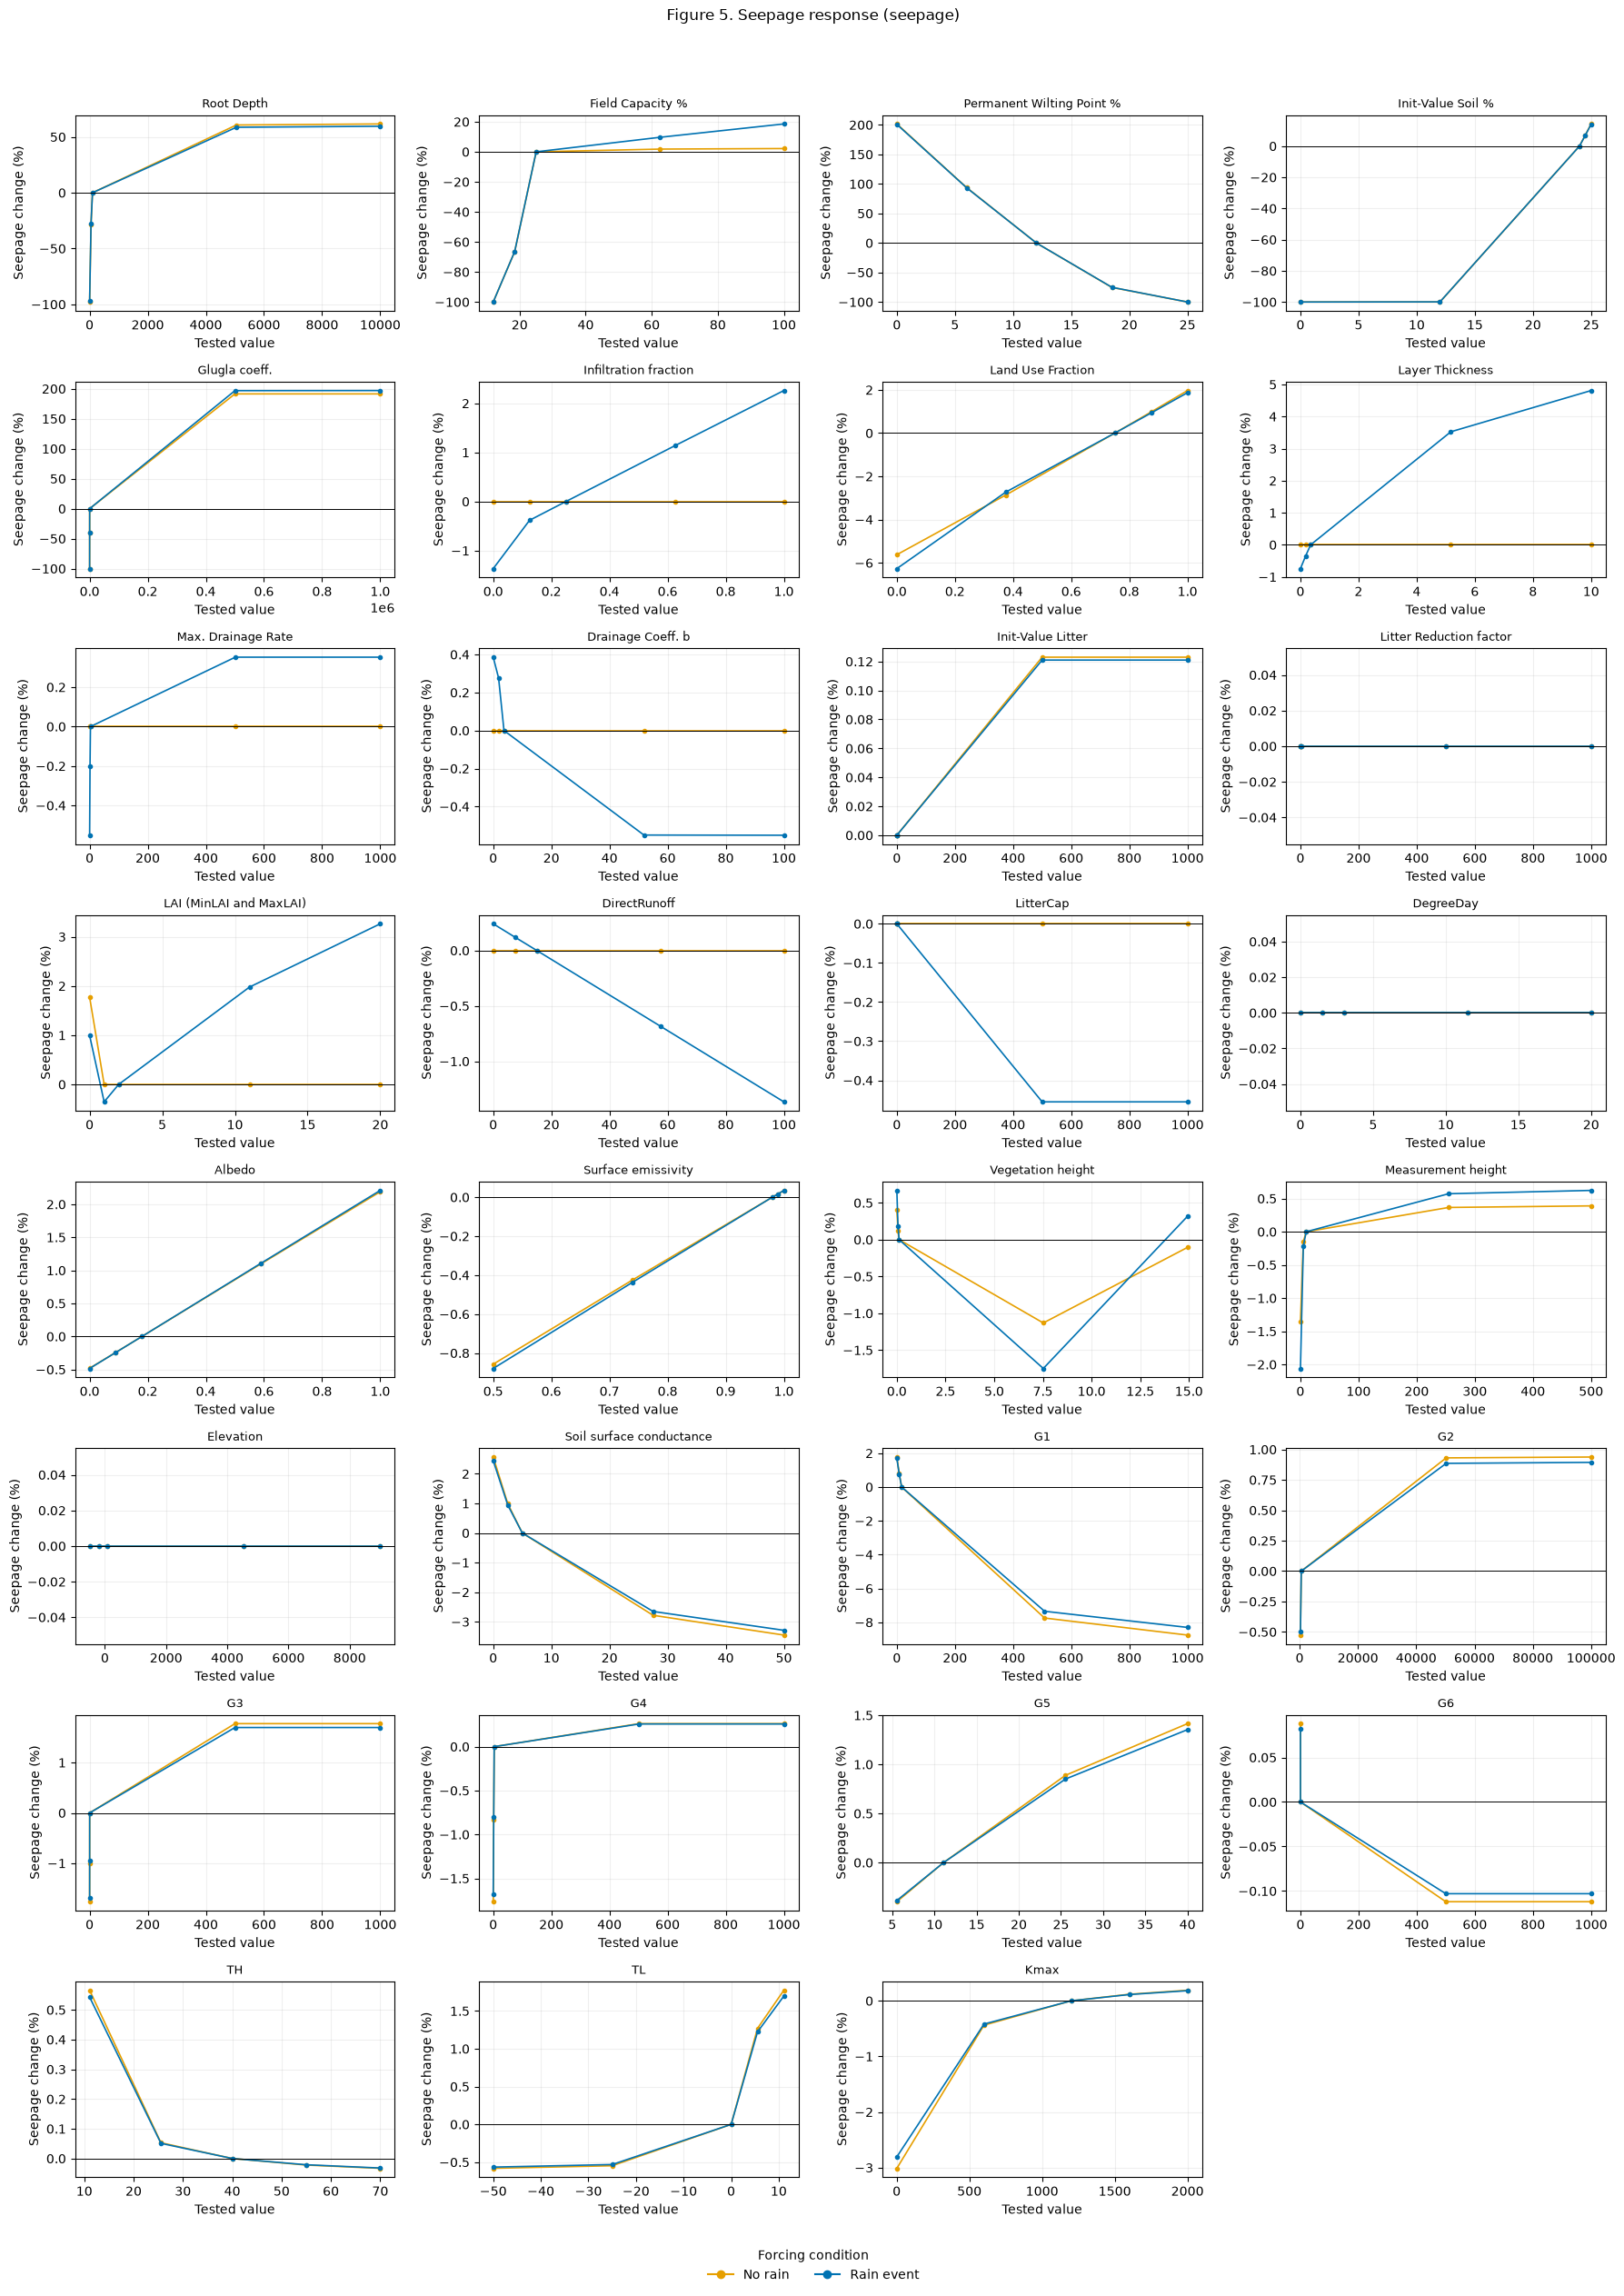

In [16]:
metric_titles = [
    ("ETaTotal", "total actual evapotranspiration"),
    ("Runoff_total", "total runoff"),
    ("Seepage", "seepage"),
]
columns = 4
rows = int(np.ceil(len(parameter_order) / columns))

for figure_number, (metric, description) in enumerate(metric_titles, start=3):
    change_column = f"{metric}_change_%"
    if not all(change_column in table.columns for table in sensitivity.values()):
        print(f"Skipping {metric}: its change column is missing.")
        continue
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3.2 * rows), squeeze=False)
    for ax, parameter in zip(axes.ravel(), parameter_order):
        for scenario, table in sensitivity.items():
            subset = table.loc[table["parameter"] == parameter].copy()
            subset["level"] = pd.Categorical(subset["level"], LEVEL_ORDER, ordered=True)
            subset = subset.sort_values("level")
            ax.plot(subset["value"], subset[change_column], marker="o", markersize=3,
                    linewidth=1.2, color=SCENARIO_COLORS[scenario], label=scenario)
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(parameter, fontsize=9)
        ax.set_xlabel("Tested value")
        ax.set_ylabel(f"{metric} change (%)")
        ax.grid(alpha=0.2)
    for ax in axes.ravel()[len(parameter_order):]:
        ax.set_visible(False)
    handles = [Line2D([0], [0], color=SCENARIO_COLORS[name], marker="o", label=name)
               for name in SCENARIOS]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.008),
               ncol=len(handles), frameon=False, title="Forcing condition")
    fig.suptitle(f"Figure {figure_number}. {metric} response ({description})", y=0.99)
    fig.tight_layout(rect=(0, 0.035, 1, 0.97))
    plt.show()